# OSM coverage of hospitals & schools — combined plots (RQ2)

This notebook does not recompute anything. It reads the exports of the two coverage notebooks and shows hospitals and schools side by side in combined figures and tables.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

# --- Plot style (consistent across all notebooks of the thesis) ---
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

INK, INK_SECONDARY, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
MAP_BG = "#d6d5ce"                    # map background (lowest class), slightly darker than GRID
HOSPITAL_COLOR = "#d03b3b"
SCHOOL_COLOR = "#5598e7"

MODELS = {
    "hospital": {"label": "Health facilities", "color": HOSPITAL_COLOR},
    "school":   {"label": "Schools",           "color": SCHOOL_COLOR},
}
VARIANTS = ["nepal", "aoa"]
VARIANT_LABELS = {"nepal": "All Nepal", "aoa": "AOA"}   # for plot titles
# Groupings from section 4 of the coverage notebooks (abbreviation in the file name -> plot title)
GROUPINGS = {"province": "province", "type": "municipality type", "hazard": "hazard zone"}
REFERENCE_ROWS = ["Nepal (alle Gemeinden)", "Nepal (alle Pixel)"]

data_dir = Path(r"C:\Users\MarcComagic\OneDrive - Universität Zürich UZH\Masterarbeit\Data")
coverage_dir = data_dir / "osm_coverage"
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)


def save_fig(fig, name):
    """Save the figure as PDF and PNG in figures/."""
    fig.savefig(fig_dir / f"coverage_combined_{name}.pdf")
    fig.savefig(fig_dir / f"coverage_combined_{name}.png")

## 2. Load data

### 2.1 Municipality table

Both notebooks use the same 704 municipalities with the same groupings — the cell checks this. Then one flat table `muni`: one row per municipality, with variant and model as suffix of the metrics (e.g. `CR_aoa_school`).

In [2]:
BASE_COLS = ["osm_id", "gemeinde", "municipality_type", "province", "district", "hazard_zone", "n_pixels"]
VALUE_COLS = [f"{col}_{variant}" for variant in VARIANTS for col in ["pred_pos", "osm_pos", "CR"]]

muni_by_model = {key: pd.read_csv(coverage_dir / f"{key}_coverage_municipalities.csv")
                 .sort_values("osm_id").reset_index(drop=True) for key in MODELS}
pd.testing.assert_frame_equal(muni_by_model["hospital"][BASE_COLS], muni_by_model["school"][BASE_COLS])

muni = muni_by_model["hospital"][BASE_COLS]
for key in MODELS:
    muni = muni.merge(muni_by_model[key][["osm_id"] + VALUE_COLS]
                      .rename(columns={col: f"{col}_{key}" for col in VALUE_COLS}), on="osm_id")

print(f"Municipalities: {len(muni)}")
print(muni.filter(regex="^(pred_pos|osm_pos)_").sum().astype(int).to_string())

Municipalities: 704
pred_pos_nepal_hospital     1020
osm_pos_nepal_hospital      1215
pred_pos_aoa_hospital        567
osm_pos_aoa_hospital         596
pred_pos_nepal_school      11725
osm_pos_nepal_school       19017
pred_pos_aoa_school         7617
osm_pos_aoa_school         12640


### 2.2 Aggregation by group

In [3]:
AGG_COLS = ["pred_pos_total", "osm_pos_total", "CR_pooled", "CR_ci_low", "CR_ci_high", "CR_index", "rang"]

agg = None
for key in MODELS:
    for variant in VARIANTS:
        part = pd.concat([
            pd.read_csv(coverage_dir / f"{key}_agg_{grouping}_{variant}.csv", index_col=0)
            .rename_axis("gruppe").reset_index().assign(gruppierung=grouping)
            for grouping in GROUPINGS
        ])
        part = part[["gruppierung", "gruppe", "n_gemeinden"] + AGG_COLS] \
            .rename(columns={col: f"{col}_{variant}_{key}" for col in AGG_COLS})
        if agg is None:
            agg = part
        else:
            n_before = len(agg)
            agg = agg.merge(part.drop(columns="n_gemeinden"), on=["gruppierung", "gruppe"], how="left")
            assert len(agg) == n_before and agg[f"CR_pooled_{variant}_{key}"].notna().any()
agg = agg.reset_index(drop=True)

show = ["gruppierung", "gruppe", "n_gemeinden"] + [f"{col}_{variant}_{key}" for variant in VARIANTS
                                                    for key in MODELS for col in ["CR_pooled", "rang"]]
agg[show].style.hide(axis="index").format(precision=2, na_rep="")

gruppierung,gruppe,n_gemeinden,CR_pooled_nepal_hospital,rang_nepal_hospital,CR_pooled_nepal_school,rang_nepal_school,CR_pooled_aoa_hospital,rang_aoa_hospital,CR_pooled_aoa_school,rang_aoa_school
province,Lumbini,106.00,2.28,1.00,2.97,1.00,2.04,1.00,2.67,1.00
province,Sudurpashchim,88.00,1.61,2.00,1.77,3.00,1.28,3.00,1.62,4.00
province,Karnali,55.00,1.59,3.00,1.03,6.00,1.85,2.00,1.04,6.00
province,Bagmati,99.00,1.14,4.00,2.23,2.00,0.68,5.00,2.59,2.00
province,Gandaki,84.00,1.11,5.00,1.12,5.00,0.99,4.00,1.12,5.00
province,Koshi,137.00,0.73,6.00,0.77,7.00,0.30,7.00,0.66,7.00
province,Madhesh,135.00,0.59,7.00,1.44,4.00,0.43,6.00,1.76,3.00
province,Nepal (alle Gemeinden),704.00,1.19,,1.62,,1.05,,1.66,
province,Nepal (alle Pixel),,1.22,,1.62,,1.06,,1.66,
type,Metropolitan City,3.00,3.26,1.00,1.30,3.00,,,1.67,3.00


## 3. Metrics per municipality

### 3.1 How small are the denominators? Distribution of `pred_pos` and `osm_pos`

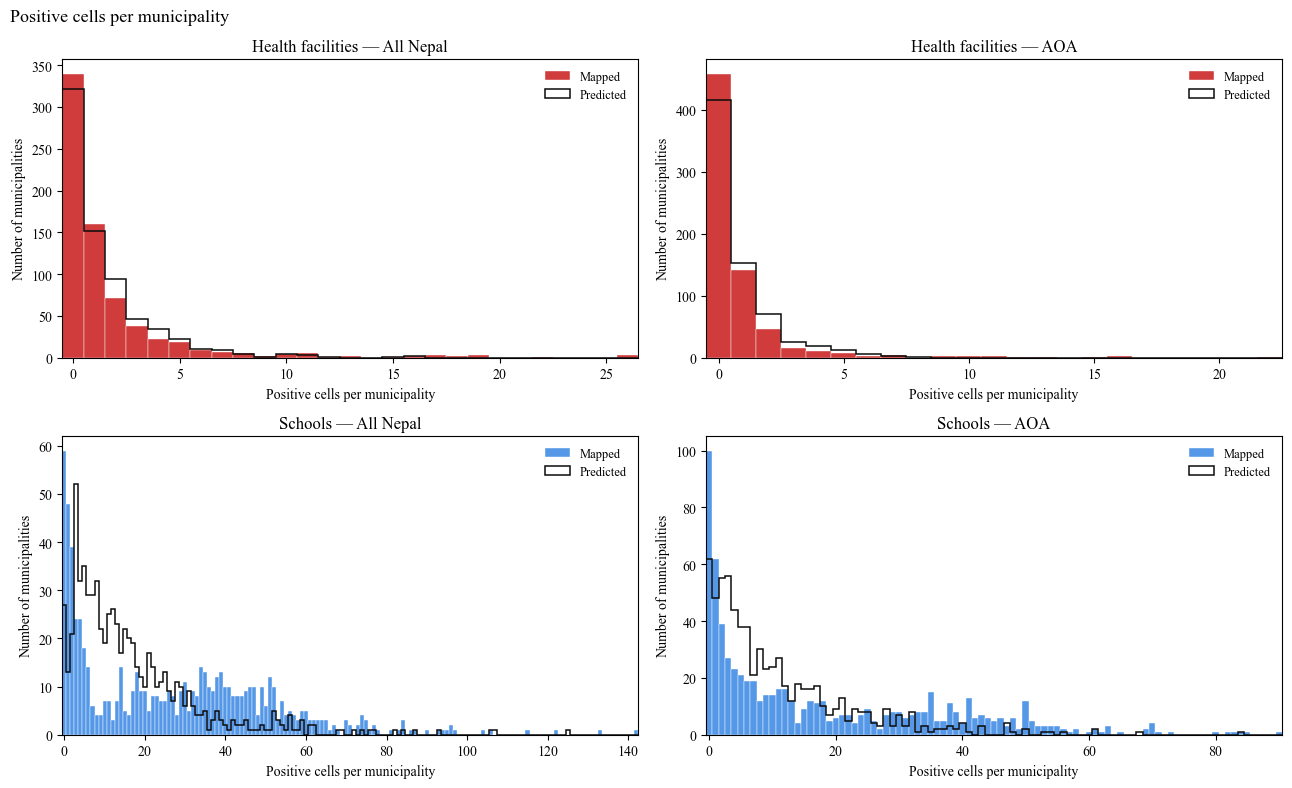

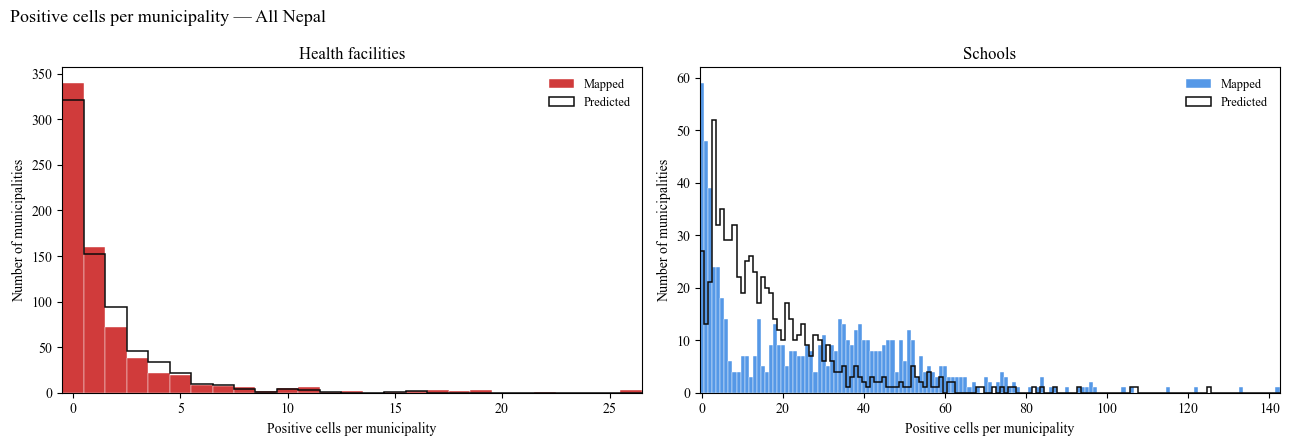

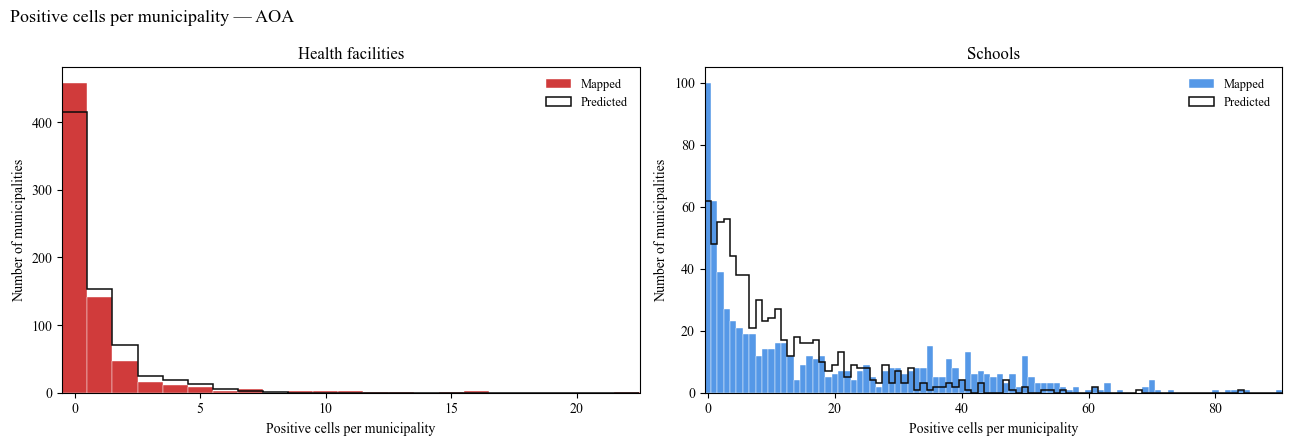

In [4]:
def plot_count_hist(ax, key, variant):
    # OSM as filled bars, prediction as outline on top -> both distributions in one panel
    pred, osm = muni[f"pred_pos_{variant}_{key}"], muni[f"osm_pos_{variant}_{key}"]
    x_max = int(max(pred.max(), osm.max()))
    bins = np.arange(-0.5, x_max + 1.5, 1)   # one bar per integer (0, 1, 2, ...)
    ax.hist(osm, bins=bins, color=MODELS[key]["color"], edgecolor="white", linewidth=0.3,
            label="Mapped")
    ax.hist(pred, bins=bins, histtype="step", color=INK, linewidth=1.1,
            label="Predicted")
    ax.set_xlim(-0.5, x_max + 0.5)
    ax.set_title(MODELS[key]["label"])
    ax.set_xlabel("Positive cells per municipality")
    ax.set_ylabel("Number of municipalities")
    ax.legend(frameon=False)


# Both variants: rows = model, columns = all Nepal / AOA
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, key in zip(axes, MODELS):
    for ax, variant in zip(row, VARIANTS):
        plot_count_hist(ax, key, variant)
        ax.set_title(f"{MODELS[key]['label']} — {VARIANT_LABELS[variant]}")   # otherwise the columns cannot be told apart
fig.suptitle("Positive cells per municipality", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
save_fig(fig, "cells_per_municipality")
plt.show()

# Each variant separately
for variant in VARIANTS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key in zip(axes, MODELS):
        plot_count_hist(ax, key, variant)
    fig.suptitle(f"Positive cells per municipality — {VARIANT_LABELS[variant]}", x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    save_fig(fig, f"cells_per_municipality_{variant}")
    plt.show()

### 3.2 Distribution of the CR

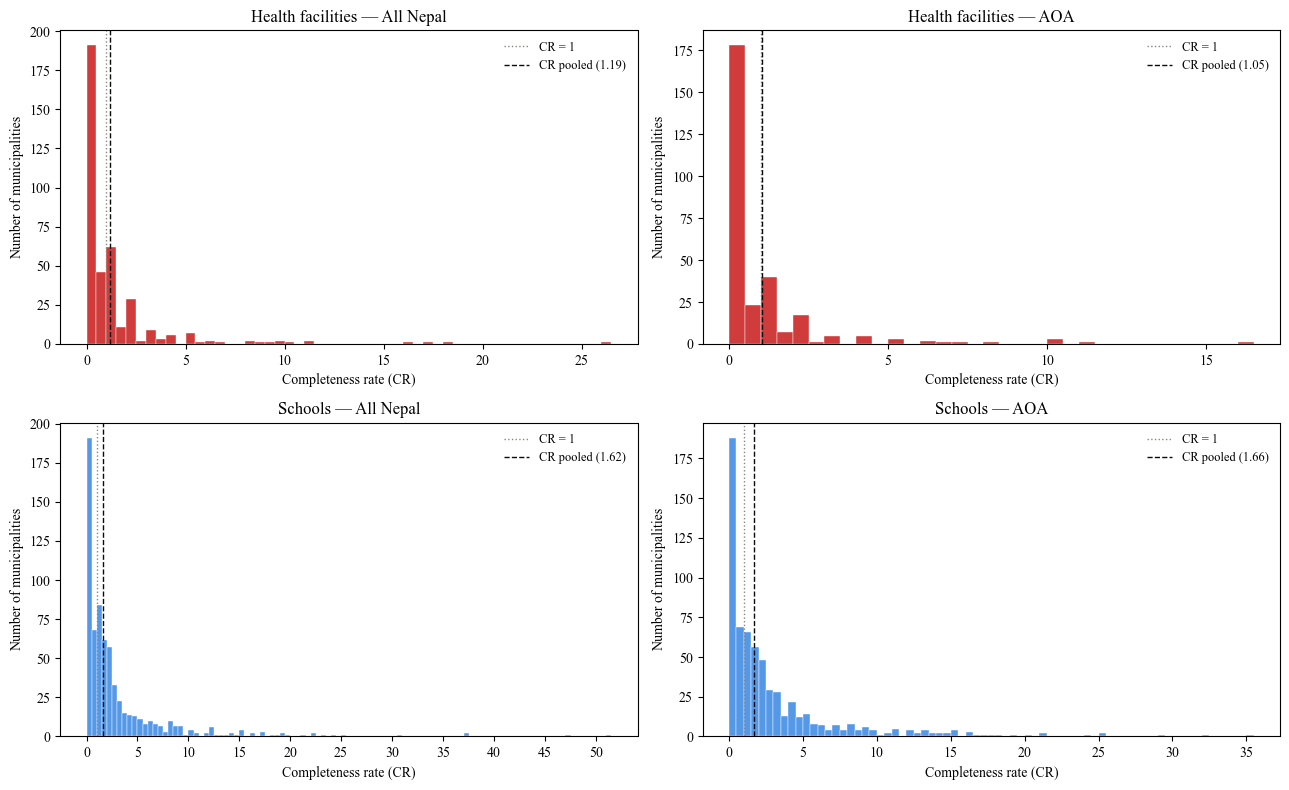

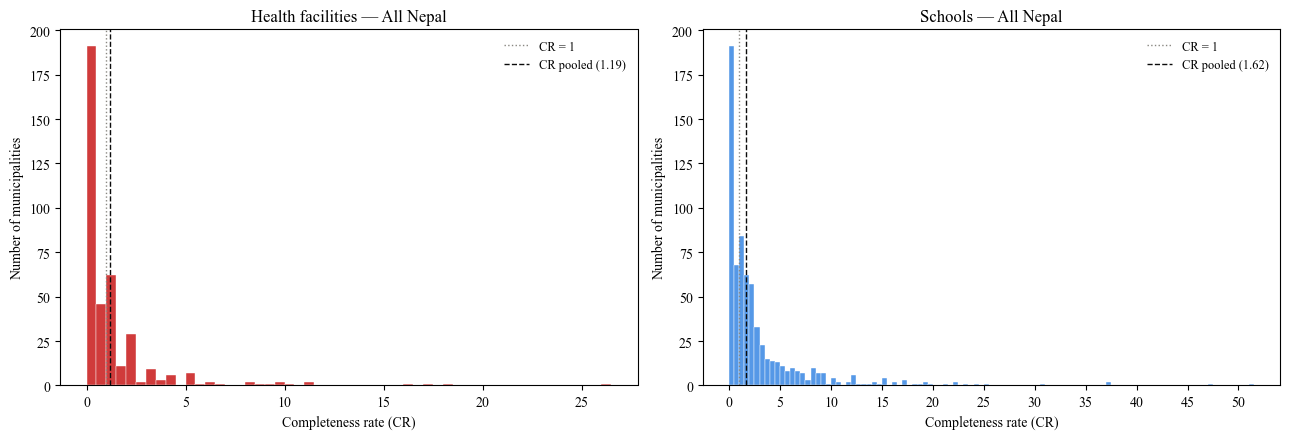

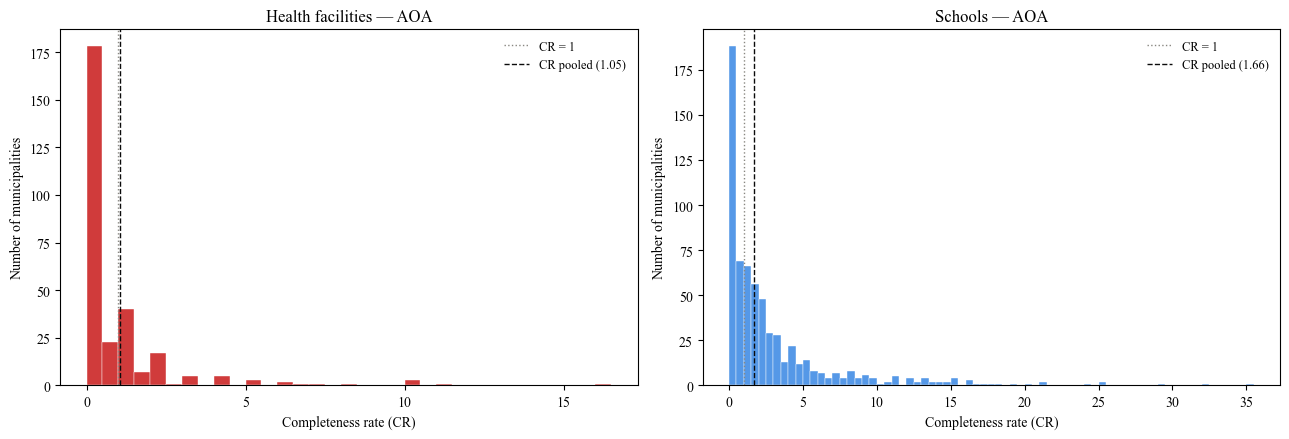

In [5]:
CR_BIN_WIDTH = 0.5


def plot_cr_hist(ax, key, variant):
    cr = muni[f"CR_{variant}_{key}"]
    cr_pooled = muni[f"osm_pos_{variant}_{key}"].sum() / muni[f"pred_pos_{variant}_{key}"].sum()
    # Classes [0, 0.5), [0.5, 1), ... up to beyond the maximum
    bins = np.arange(0, cr.max() + 2 * CR_BIN_WIDTH, CR_BIN_WIDTH)
    ax.hist(cr.dropna(), bins=bins, color=MODELS[key]["color"], edgecolor="white", linewidth=0.3)
    ax.axvline(1, ls=":", color=MUTED, lw=1, label="CR = 1")
    ax.axvline(cr_pooled, ls="--", color=INK, lw=1, label=f"CR pooled ({cr_pooled:.2f})")
    ax.xaxis.set_major_locator(MultipleLocator(5))   # labels only at 0, 5, 10, ...
    ax.set_title(f"{MODELS[key]['label']} — {VARIANT_LABELS[variant]}")
    ax.set_xlabel("Completeness rate (CR)"); ax.set_ylabel("Number of municipalities")
    ax.legend(frameon=False)


# Both variants: rows = model, columns = all Nepal / AOA
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, key in zip(axes, MODELS):
    for ax, variant in zip(row, VARIANTS):
        plot_cr_hist(ax, key, variant)
fig.tight_layout()
save_fig(fig, "cr_hist")
plt.show()

# Each variant separately
for variant in VARIANTS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, key in zip(axes, MODELS):
        plot_cr_hist(ax, key, variant)
    fig.tight_layout()
    save_fig(fig, f"cr_hist_{variant}")
    plt.show()

### 3.3 Map of the municipality CR

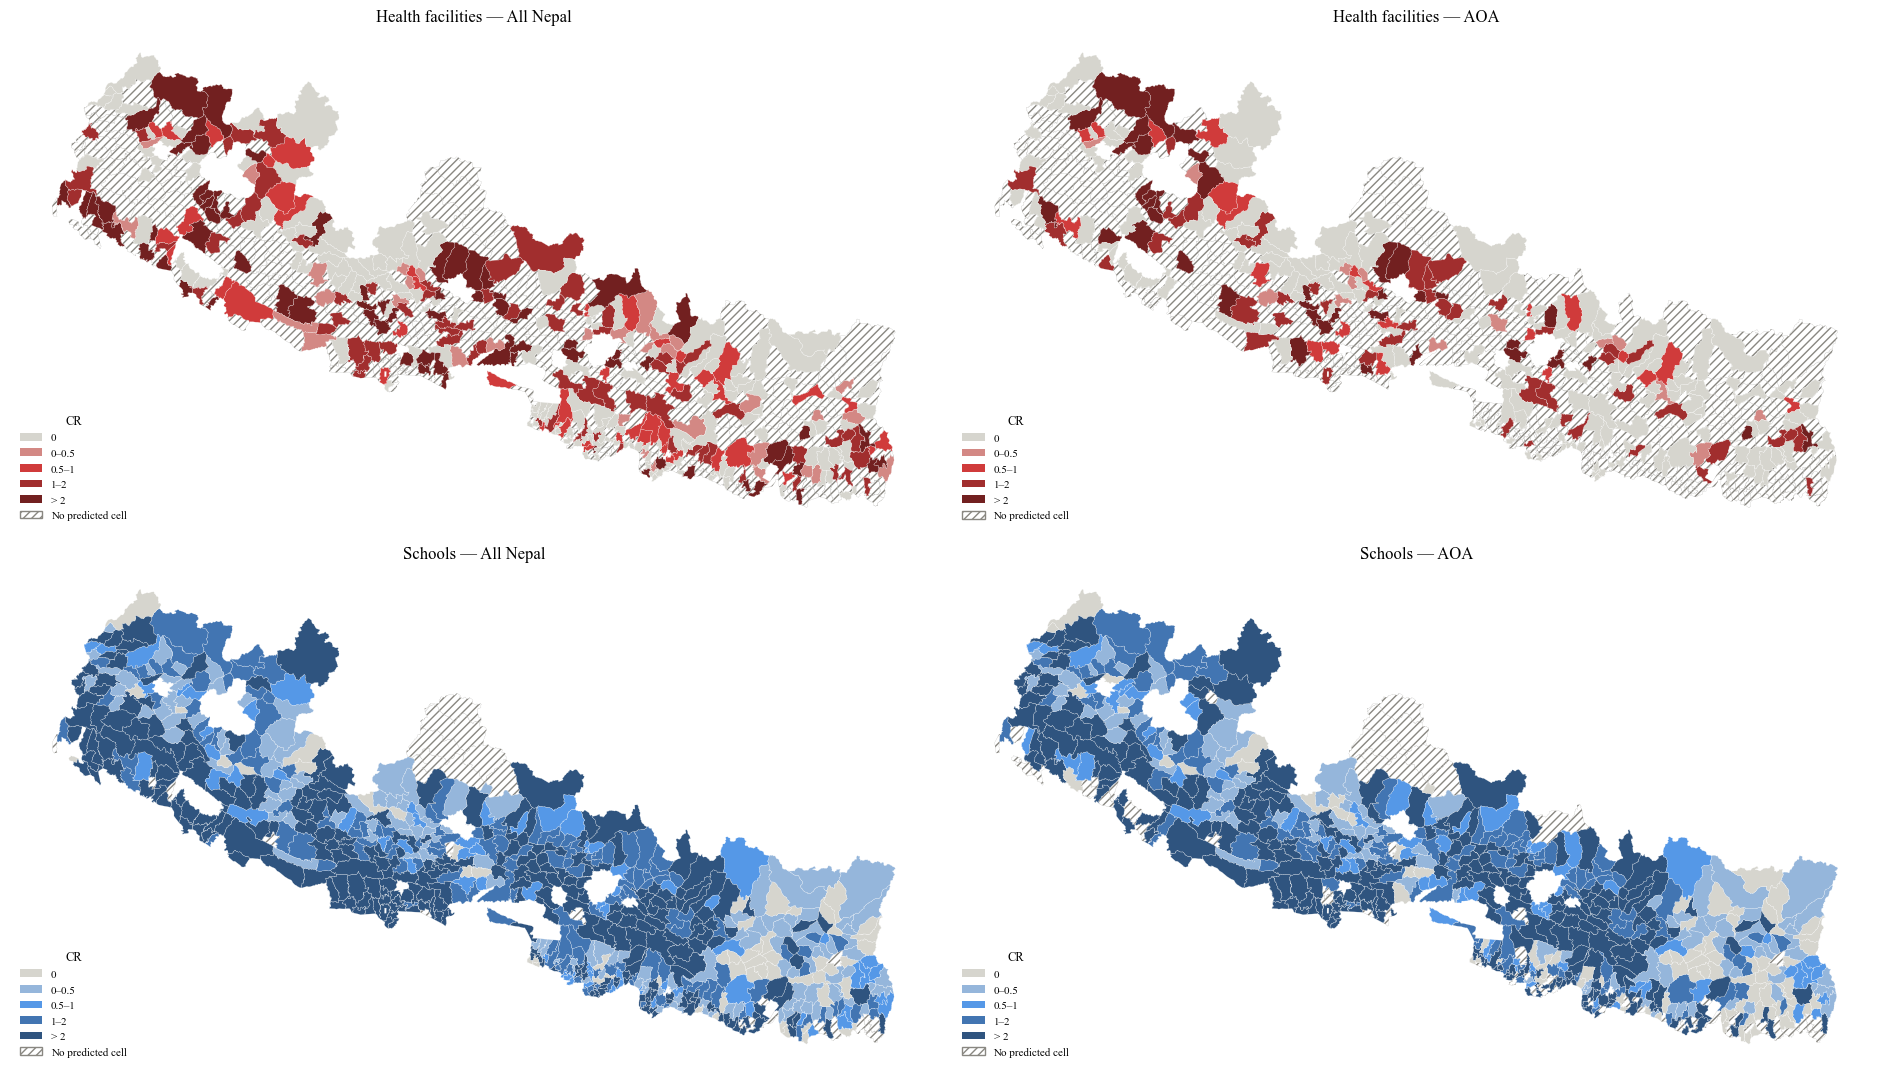

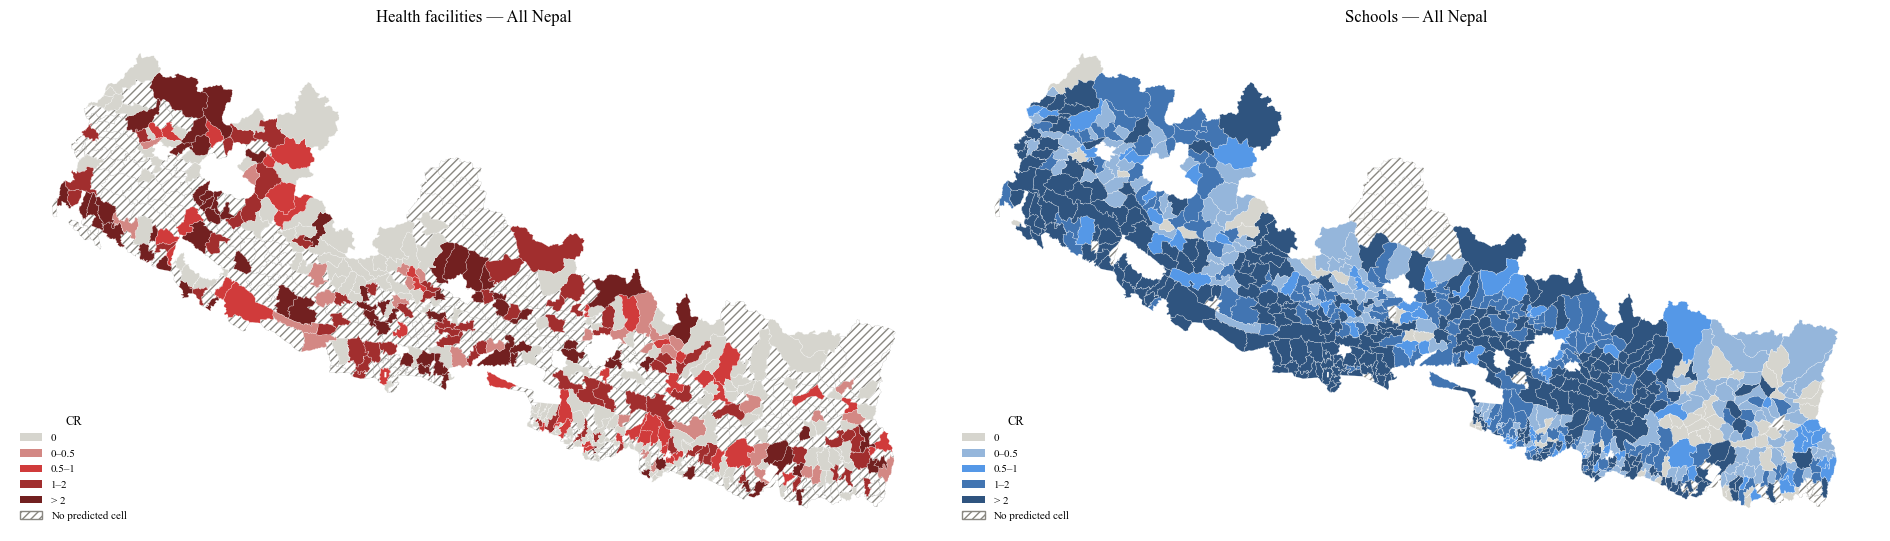

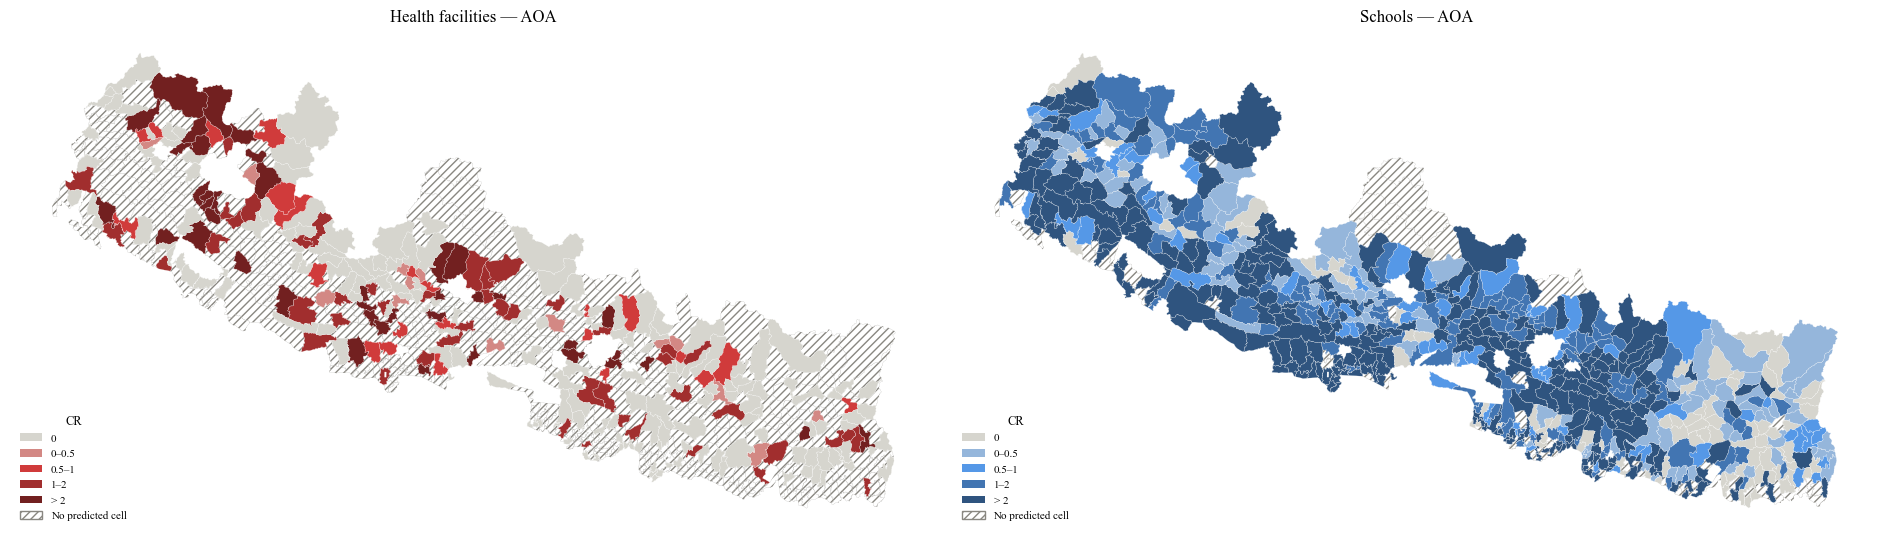

In [6]:
CR_BINS = [0, 1e-9, 0.5, 1, 2, np.inf]
CR_CLASSES = ["0", "0–0.5", "0.5–1", "1–2", "> 2"]

geoms = gpd.read_file(coverage_dir / "hospital_coverage_municipalities.gpkg", columns=["osm_id"])
muni_map = geoms.merge(muni, on="osm_id", how="right")
assert muni_map.geometry.notna().all() and len(muni_map) == len(muni)


def plot_cr_map(ax, key, variant):
    color = MODELS[key]["color"]
    # MAP_BG -> model colour -> darker model colour, so that the middle classes are clearly distinguishable
    dark = mpl.colors.to_rgb(color) * np.array(0.55)
    class_colors = LinearSegmentedColormap.from_list(key, [MAP_BG, color, dark])(np.linspace(0, 1, len(CR_CLASSES)))
    cr = muni_map[f"CR_{variant}_{key}"]
    classes = pd.cut(cr, CR_BINS, labels=False, right=False)   # [0, 1e-9) = exactly 0, otherwise [a, b)
    no_cr = cr.isna()
    muni_map[no_cr].plot(ax=ax, facecolor="white", edgecolor=MUTED, hatch="////", linewidth=0.1)
    muni_map[~no_cr].plot(ax=ax, color=class_colors[classes[~no_cr].astype(int)],
                          edgecolor="white", linewidth=0.15)
    handles = [Patch(facecolor=c, label=label) for c, label in zip(class_colors, CR_CLASSES)]
    handles.append(Patch(facecolor="white", edgecolor=MUTED, hatch="////", label="No predicted cell"))
    ax.legend(handles=handles, title="CR", loc="lower left", frameon=False, fontsize=8, title_fontsize=9)
    ax.set_title(f"{MODELS[key]['label']} — {VARIANT_LABELS[variant]}")
    ax.axis("off")


# Both variants: rows = model, columns = all Nepal / AOA
fig, axes = plt.subplots(2, 2, figsize=(19, 11))
for row, key in zip(axes, MODELS):
    for ax, variant in zip(row, VARIANTS):
        plot_cr_map(ax, key, variant)
fig.tight_layout()
save_fig(fig, "cr_map")
plt.show()

# Each variant separately
for variant in VARIANTS:
    fig, axes = plt.subplots(1, 2, figsize=(19, 6))
    for ax, key in zip(axes, MODELS):
        plot_cr_map(ax, key, variant)
    fig.tight_layout()
    save_fig(fig, f"cr_map_{variant}")
    plt.show()

## 4. Comparison by province, municipality type and hazard zone

### 4.1 Figure: CR by group

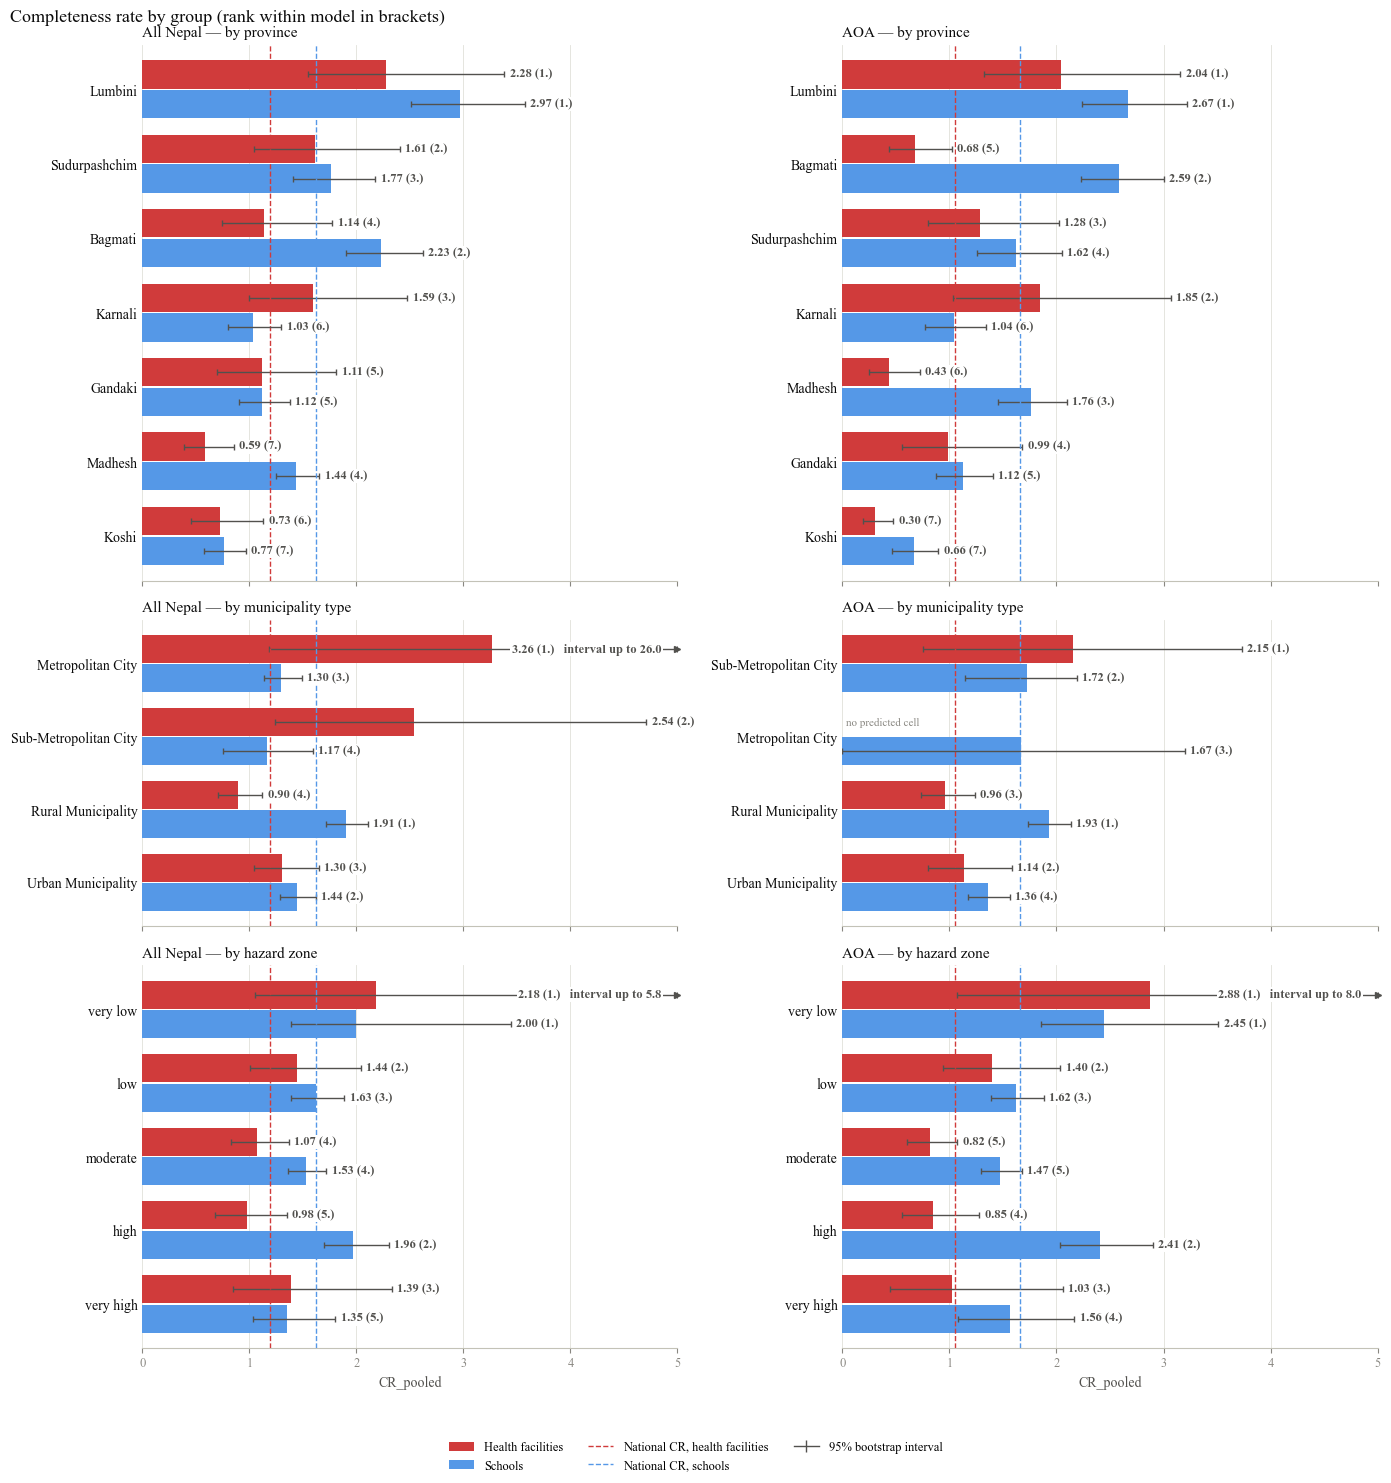

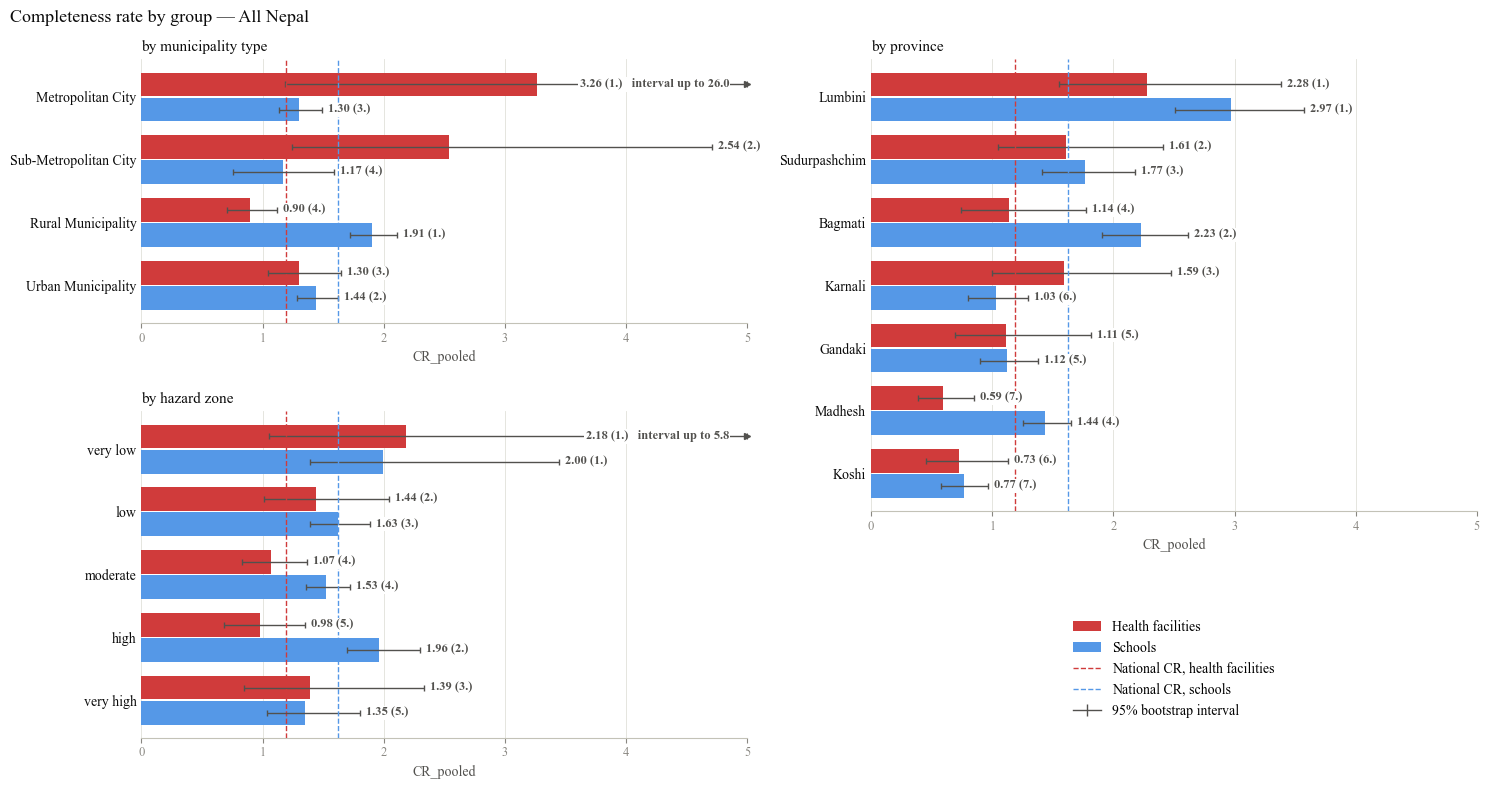

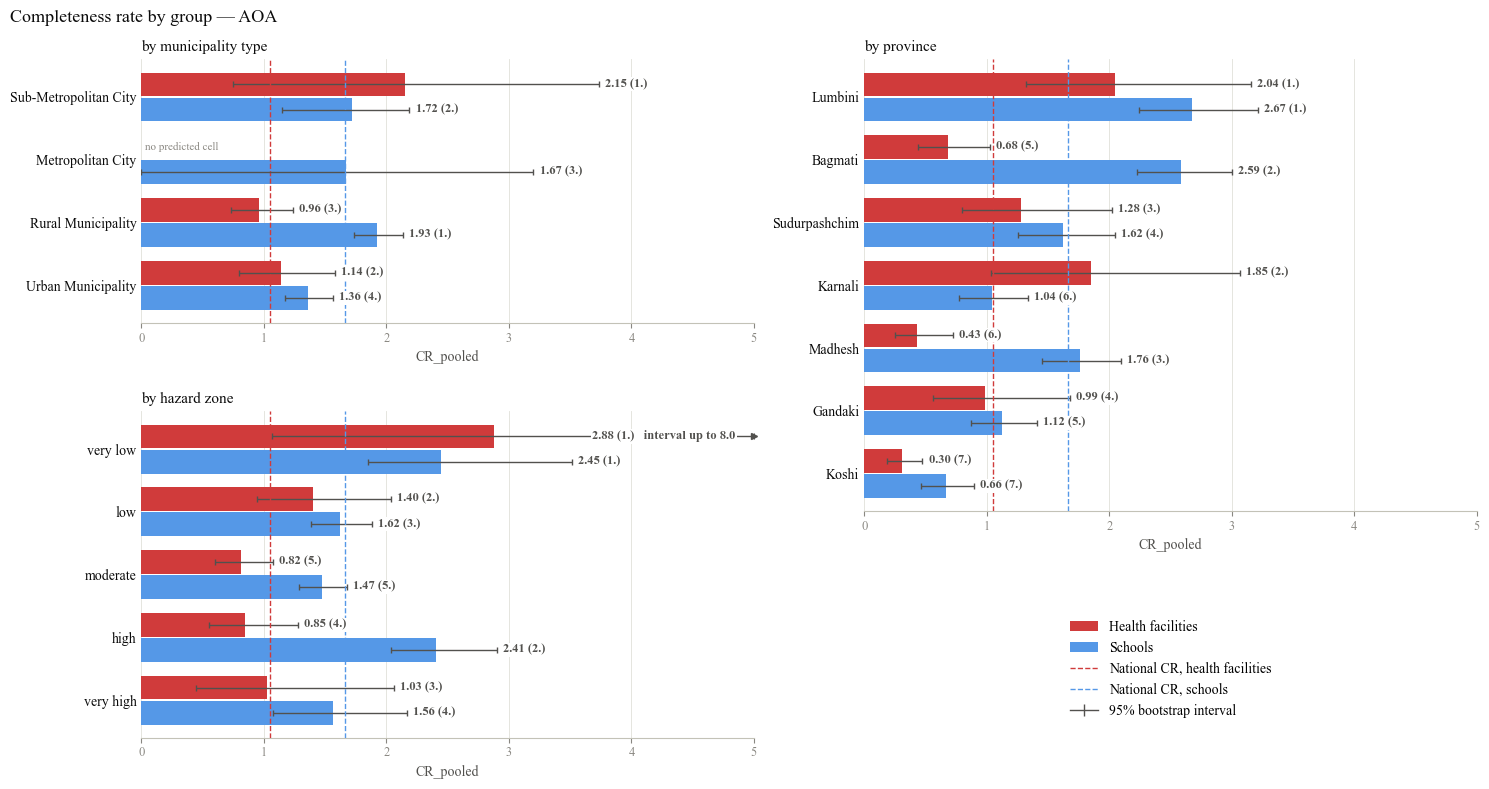

In [7]:
X_MAX = 5
BAR_HEIGHT = 0.38
OFFSETS = {"hospital": 0.2, "school": -0.2}
LABEL_BOX = dict(facecolor="white", edgecolor="none", pad=1)
HEIGHT_RATIOS = [7, 4, 5]


def plot_cr_panel(ax, grouping, variant, with_variant=False):
    rows = agg[agg["gruppierung"] == grouping].set_index("gruppe")
    groups = rows.drop(index=REFERENCE_ROWS)
    if grouping != "hazard":
        mean_cr = groups[[f"CR_pooled_{variant}_{key}" for key in MODELS]].mean(axis=1)
        groups = groups.loc[mean_cr.sort_values(ascending=False).index]
    y = np.arange(len(groups))[::-1]   # first row at the top

    for key, m in MODELS.items():
        yk = y + OFFSETS[key]
        cr = groups[f"CR_pooled_{variant}_{key}"]
        low, high = groups[f"CR_ci_low_{variant}_{key}"], groups[f"CR_ci_high_{variant}_{key}"]
        clipped = (high > X_MAX).to_numpy()

        ax.barh(yk, cr.fillna(0), height=BAR_HEIGHT, color=m["color"], zorder=2)
        ax.errorbar(cr, yk, xerr=[cr - low, high.clip(upper=X_MAX) - cr],
                    fmt="none", ecolor=INK_SECONDARY, elinewidth=1, capsize=2, zorder=3)
        if clipped.any():
            ax.plot([X_MAX] * clipped.sum(), yk[clipped], ">", color=INK_SECONDARY,
                    markersize=5, clip_on=False, zorder=3)
        for yi, value, hi, rang in zip(yk, cr, high, groups[f"rang_{variant}_{key}"]):
            if pd.isna(value):
                ax.text(0.03, yi, "no predicted cell", va="center", fontsize=8, color=MUTED,
                        bbox=LABEL_BOX, zorder=4)
            elif hi > X_MAX:
                ax.text(X_MAX - 0.15, yi, f"{value:.2f} ({int(rang)}.)   interval up to {hi:.1f}",
                        ha="right", va="center", fontsize=9, fontweight="bold", color=INK_SECONDARY, bbox=LABEL_BOX, zorder=4)
            else:
                ax.text(hi + 0.05, yi, f"{value:.2f} ({int(rang)}.)", va="center",
                        fontsize=9, fontweight="bold", color=INK_SECONDARY, bbox=LABEL_BOX, zorder=4)

        national = rows.loc["Nepal (alle Gemeinden)", f"CR_pooled_{variant}_{key}"]
        ax.axvline(national, color=m["color"], lw=1, ls="--", zorder=3)

    ax.set_yticks(y, groups.index, fontsize=10, color=INK)
    ax.set_ylim(y.min() - 0.6, y.max() + 0.6)
    title = f"by {GROUPINGS[grouping]}"
    if with_variant:   # overview with both variants: otherwise the columns cannot be told apart
        title = f"{VARIANT_LABELS[variant]} — {title}"
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlim(0, X_MAX)
    ax.grid(axis="x", color=GRID, lw=0.6, zorder=0)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", colors=MUTED, labelsize=9)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")


def legend_handles():
    handles = [Patch(facecolor=m["color"], label=m["label"]) for m in MODELS.values()]
    handles += [Line2D([], [], color=m["color"], lw=1, ls="--", label=f"National CR, {m['label'].lower()}")
                for m in MODELS.values()]
    handles.append(Line2D([], [], color=INK_SECONDARY, lw=1, marker="|", markersize=8, label="95% bootstrap interval"))
    return handles


def finish_figure(fig, axes, suptitle, name, legend_ax=None):
    # legend_ax: free panel for the legend; otherwise the legend goes below the figure
    for ax in axes:
        ax.set_xlabel("CR_pooled", color=INK_SECONDARY, fontsize=10)
    if legend_ax is None:
        fig.legend(handles=legend_handles(), loc="lower center", ncol=3, frameon=False, fontsize=9)
        rect = [0, 0.05, 1, 1]
    else:
        legend_ax.axis("off")
        legend_ax.legend(handles=legend_handles(), loc="center", frameon=False, fontsize=10)
        rect = [0, 0, 1, 1]
    fig.suptitle(suptitle, x=0.01, ha="left", fontsize=13, color=INK)
    fig.tight_layout(rect=rect)
    save_fig(fig, name)
    plt.show()


# Both variants: all Nepal on the left, AOA on the right
fig, axes = plt.subplots(3, 2, figsize=(14, 15), sharex=True, gridspec_kw={"height_ratios": HEIGHT_RATIOS})
for row, grouping in zip(axes, GROUPINGS):
    for ax, variant in zip(row, VARIANTS):
        plot_cr_panel(ax, grouping, variant, with_variant=True)
finish_figure(fig, axes[-1], "Completeness rate by group (rank within model in brackets)", "cr_by_group")

# Each variant separately: municipality type above hazard zone on the left, province above the legend on the right (top-aligned).
# The row heights correspond to the number of groups (+ 1.2 margin, as in set_ylim) and both columns
# have the same sum -> equally thick bars in all three panels.
N_GROUPS = {"type": 4, "hazard": 5, "province": 7}
span = {grouping: n + 0.2 for grouping, n in N_GROUPS.items()}   # (n - 1) + 2 * 0.6
legend_span = span["type"] + span["hazard"] - span["province"]

for variant in VARIANTS:
    fig = plt.figure(figsize=(15, 8))
    grid = fig.add_gridspec(1, 2)
    left = grid[0].subgridspec(2, 1, height_ratios=[span["type"], span["hazard"]], hspace=0.3)
    right = grid[1].subgridspec(2, 1, height_ratios=[span["province"], legend_span], hspace=0.3)
    ax_type, ax_hazard = fig.add_subplot(left[0]), fig.add_subplot(left[1])
    ax_province, ax_legend = fig.add_subplot(right[0]), fig.add_subplot(right[1])
    plot_cr_panel(ax_type, "type", variant)
    plot_cr_panel(ax_hazard, "hazard", variant)
    plot_cr_panel(ax_province, "province", variant)
    finish_figure(fig, [ax_type, ax_hazard, ax_province],
                  f"Completeness rate by group — {VARIANT_LABELS[variant]}", f"cr_by_group_{variant}",
                  legend_ax=ax_legend)

### 4.2 Spread within the groups: dissimilarity index D

In [8]:
spread = None
for key in MODELS:
    part = pd.read_csv(coverage_dir / f"{key}_spread.csv", index_col=0) \
        .rename(columns={f"D_{variant}": f"D_{variant}_{key}" for variant in VARIANTS})
    spread = part if spread is None else spread.merge(part, on=["gruppierung", "gruppe", "n_gemeinden"], how="left")
spread = spread[["gruppierung", "gruppe", "n_gemeinden"]
                + [f"D_{variant}_{key}" for variant in VARIANTS for key in MODELS]]
spread.style.hide(axis="index").format(precision=2, na_rep="")

gruppierung,gruppe,n_gemeinden,D_nepal_hospital,D_nepal_school,D_aoa_hospital,D_aoa_school
Provinz,Lumbini,106,0.60,0.35,0.64,0.34
Provinz,Sudurpashchim,88,0.62,0.42,0.70,0.45
Provinz,Karnali,55,0.52,0.33,0.61,0.38
Provinz,Bagmati,99,0.57,0.31,0.69,0.31
Provinz,Gandaki,84,0.66,0.39,0.73,0.43
Provinz,Koshi,137,0.66,0.49,0.77,0.60
Provinz,Madhesh,135,0.58,0.32,0.88,0.41
Gemeindetyp,Metropolitan City,3,0.54,0.06,,0.22
Gemeindetyp,Sub-Metropolitan City,9,0.42,0.21,0.38,0.17
Gemeindetyp,Urban Municipality,251,0.58,0.37,0.70,0.40


### 4.3 Kruskal-Wallis test

In [9]:
kruskal_wallis = pd.concat(
    [pd.read_csv(coverage_dir / f"{key}_kruskal_wallis.csv", index_col="gruppierung").add_suffix(f"_{key}")
     for key in MODELS], axis=1)
kruskal_wallis = kruskal_wallis[[f"{col}_{variant}_{key}" for variant in VARIANTS for key in MODELS
                                 for col in ["n", "chi_squared", "df", "p_value"]]]
kruskal_wallis.style.format({col: "{:.3g}" for col in kruskal_wallis.columns if col.startswith("p_value")}
                            | {col: "{:.2f}" for col in kruskal_wallis.columns if col.startswith("chi_squared")})

,n_nepal_hospital,chi_squared_nepal_hospital,df_nepal_hospital,p_value_nepal_hospital,n_nepal_school,chi_squared_nepal_school,df_nepal_school,p_value_nepal_school,n_aoa_hospital,chi_squared_aoa_hospital,df_aoa_hospital,p_value_aoa_hospital,n_aoa_school,chi_squared_aoa_school,df_aoa_school,p_value_aoa_school
gruppierung,,,,,,,,,,,,,,,,
province,383,29.35,6,5.23e-05,677,183.24,6,6.95e-37,289,31.29,6,2.23e-05,642,178.15,6,8.37e-36
municipality_type,378,41.18,3,5.99e-09,672,0.33,3,0.954,284,5.71,2,0.0577,637,1.02,3,0.797
hazard_zone,383,5.57,4,0.233,677,15.77,4,0.00334,289,5.08,4,0.279,642,25.28,4,4.43e-05


### 4.4 Spatial autocorrelation: Moran's I

In [10]:
moran = pd.concat(
    [pd.read_csv(coverage_dir / f"{key}_morans_i.csv", index_col="variante").add_suffix(f"_{key}")
     for key in MODELS], axis=1)
moran.style.format({col: "{:.3g}" if col.startswith("p_value") else "{:.3f}"
                    for col in moran.columns if not col.startswith("n_")})

,n_hospital,moran_i_hospital,std_deviate_hospital,p_value_hospital,n_school,moran_i_school,std_deviate_school,p_value_school
variante,,,,,,,,
nepal,374,0.162,3.943,4.02e-05,677,0.286,11.976,2.38e-33
aoa,271,0.240,4.602,2.09e-06,642,0.341,13.312,9.81e-41
